
## The Quantum Harmonic Oscillator on a Computer 
**Senior Honours Project, Philomena McDonald s2543832**


Importing necessary functions and packages

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload means edits to the .py files in functions/ are picked up without restarting the kernel

import numpy as np
import matplotlib.pyplot as plt

from functions import (
    local_action,
    metropolis_sweep,
    harmonic,
    anharmonic,
    naive_error,
    integrated_auto_correlation,
    correlation,
    jackknife,
    energy_gap,
)

**The Harmonic Oscillator Simulation**

In [2]:
np.random.seed(42)   # keeping seed fixed 
#Defining Parameters
#Parameters w/ dimension
h = 1 
m = 1
omega = 1
hbar = 1

delta_tau = 1 #lattice spacing
N_tau = int(50/delta_tau) #size of the lattice, keeping beta=50 throughout the whole thing!

#Dimensionless Variables
m_tilde  = m * delta_tau 
h_tilde = hbar * delta_tau 
omega_tilde = omega * delta_tau

N_therm = 500 # how many of the first sweeps are discarded
N_sweeps = 20000 # how many passes are repeated
N = N_therm + N_sweeps
samples = [] # for calculating the wavefunction

#Initialising
x = []
x_2 = []

x_analytical = 0.0
R = 1 + (omega_tilde**2/2) - omega_tilde*(np.sqrt(1+omega_tilde**2/4))
x_2_analytical = (1 / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4))) * ((1+R**(N_tau))/(1-R**N_tau))

path = np.random.randn(N_tau)
total_acc_rate = []

V = harmonic(m_tilde, omega_tilde) 

#Running Metropolis-Hastings Algorithm
for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, h, m_tilde, V)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)
    if i >= N_therm:
        samples.append(total_path.copy())

# Slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)

x_truth_value = (x_mean - x_true_error <= 0 <= x_mean + x_true_error)
x_2_truth_value = (x_2_mean - x_2_true_error <= x_2_analytical <= x_2_mean + x_2_true_error)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print("")
print(f"<x>   = {x_mean:.4f} ± {x_true_error:.4f}  (naive {x_naive_error:.4f}) \
      theoretical value within range: {x_truth_value}")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_true_error:.4f}  (naive {x_2_naive_error:.4f}) \
      theoretical value within range: {x_2_truth_value}")
print(f"tau_int(x)   = {tau_x:.2f}  (W={W_x}),  N_eff = {N_sweeps/(2*tau_x):.0f}")
print(f"tau_int(x^2) = {tau_x_2:.2f}  (W={W_x_2}),  N_eff = {N_sweeps/(2*tau_x_2):.0f}")
print(f"<x> is {abs(x_mean)/x_true_error:.2f} true standard errors from 0")
print(f"<x^2> is {(x_2_mean - x_2_analytical) / x_2_true_error:.2f} true standard errors from the analytical value {np.round(x_2_analytical, 3)}")

Acceptance rate = 0.6748595121951219

<x>   = -0.0001 ± 0.0048  (naive 0.0010)       theoretical value within range: True
<x^2> = 0.4484 ± 0.0024  (naive 0.0007)       theoretical value within range: True
tau_int(x)   = 11.52  (W=58),  N_eff = 868
tau_int(x^2) = 5.19  (W=26),  N_eff = 1925
<x> is 0.01 true standard errors from 0
<x^2> is 0.50 true standard errors from the analytical value 0.447


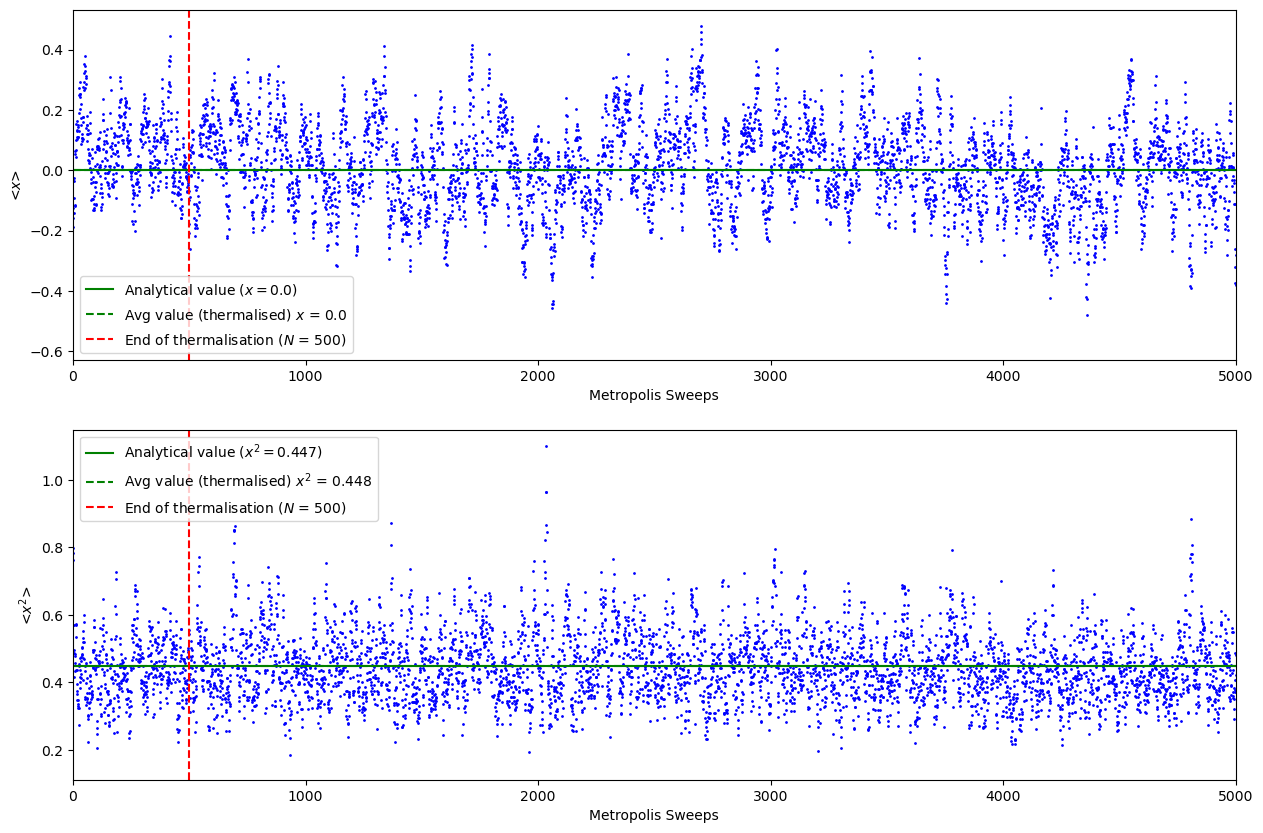

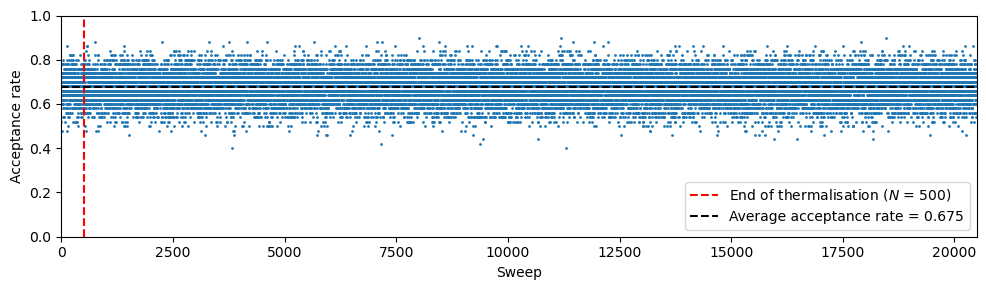

In [3]:
# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(2, 1, figsize=(15,10))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<$x$>")
ax[0].set_xlim(0, 5000)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {-np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel(rf"<$x^2$>")
ax[1].set_xlim(0, 5000)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 3)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

# Plotting the acceptance rate
plt.figure(figsize=(10,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlim(0, N_therm + N_sweeps)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()
plt.tight_layout()
plt.show()

**Ground State Wave Function**

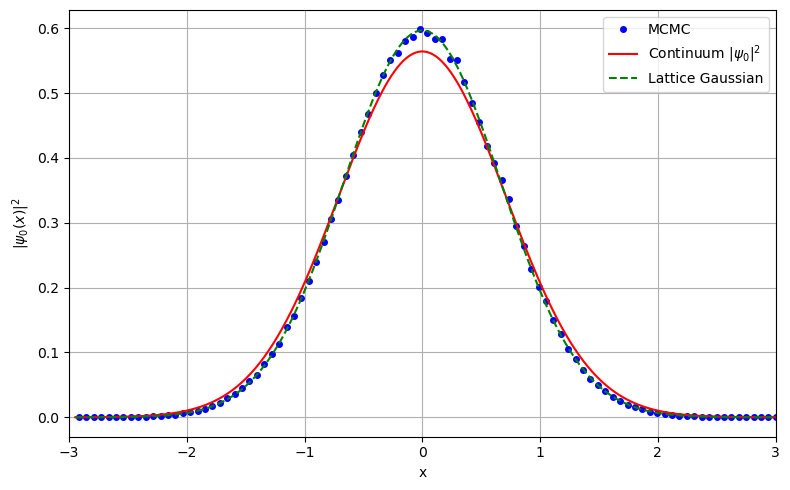

In [4]:
# continuum ground state
samples_gs = np.concatenate(samples)

x_wavefn = np.linspace(samples_gs.min(), samples_gs.max(), 500)
# continuum |psi_0|^2
psi2_cont = np.sqrt(m*omega/(np.pi*hbar)) * np.exp(-m*omega*x_wavefn**2/hbar)

#lattice-exact ground state
sigma2 = x_2_analytical
psi2_latt = np.exp(-1*(x_wavefn**2)/(2*sigma2)) / np.sqrt(2*np.pi*sigma2)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# |psi|^2, continuum gaussian
counts, edges = np.histogram(samples_gs, bins=100, density=True)
centres = 0.5 * (edges[:-1] + edges[1:])
ax.plot(centres, counts, 'o', color="blue", markersize=4, label="MCMC")
ax.plot(x_wavefn, psi2_cont, 'r-',  label=r"Continuum $|\psi_0|^2$")
ax.plot(x_wavefn, psi2_latt, 'g--', label="Lattice Gaussian")
ax.set_xlim(-3,3)
ax.set_xlabel("x"); ax.set_ylabel(r"$|\psi_0(x)|^2$")
ax.legend()
plt.grid()
plt.tight_layout()
plt.show()

**Autocorrelation**

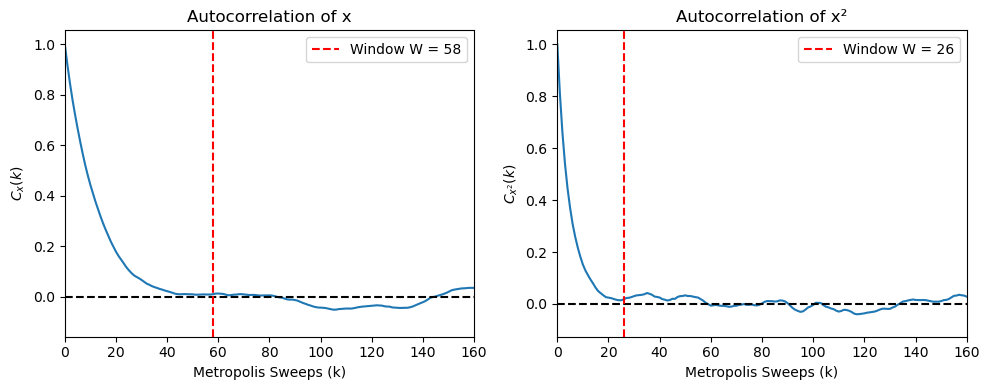

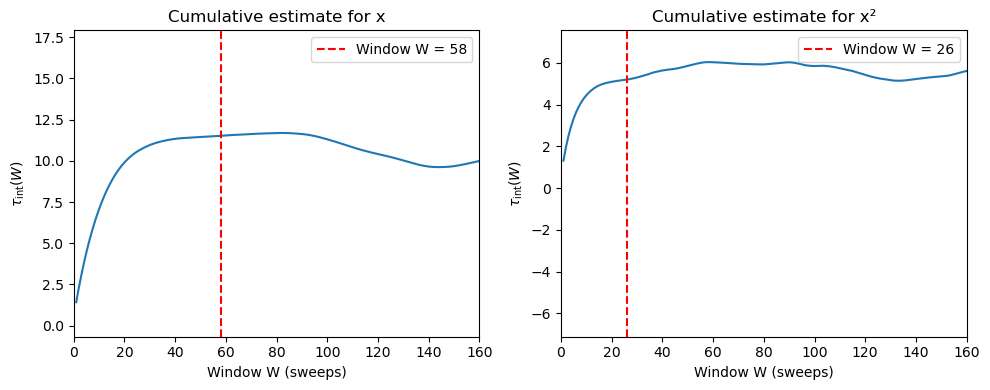

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(np.arange(len(C_x)), C_x)
ax[0].axhline(0, color="black", linestyle="--")
ax[0].axvline(W_x, color="red", linestyle="--",
              label=f"Window W = {W_x}")
ax[0].set_xlabel("Metropolis Sweeps (k)")
ax[0].set_ylabel(r"$C_x(k)$")
ax[0].set_xlim(0, 160)
ax[0].set_title("Autocorrelation of x")
ax[0].legend()

ax[1].plot(np.arange(len(C_x_2)), C_x_2)
ax[1].axhline(0, color="black", linestyle="--")
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlim(0, 160)
ax[1].set_xlabel("Metropolis Sweeps (k)")
ax[1].set_ylabel(r"$C_{x^2}(k)$")
ax[1].set_title("Autocorrelation of x²")
ax[1].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(np.arange(1, len(tau_run_x) + 1),tau_run_x)
ax[0].axvline(W_x, color="red", linestyle="--", label=f"Window W = {W_x}")
ax[0].set_xlabel("Window W (sweeps)")
ax[0].set_xlim(0, 160)
ax[0].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[0].set_title("Cumulative estimate for x")
ax[0].legend()

ax[1].plot(np.arange(1, len(tau_run_x_2) + 1), tau_run_x_2)
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlabel("Window W (sweeps)")
ax[1].set_xlim(0, 160)
ax[1].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[1].set_title("Cumulative estimate for x²")
ax[1].legend()

plt.tight_layout()
plt.show()

**Correlation Function + Energy Gap**

In [6]:
n = np.arange(N_tau)
tau = n * delta_tau
C_cont = (hbar / (2*m*omega)) * np.exp(-omega*tau)
C_analytical = (R**n + R**(N_tau-n)) / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4)*(1-R**N_tau))

x_corr = correlation(samples)
gap = energy_gap(samples)

# autocorrelation errors on C(n): for every sweep, average x_i * x_{i+n} over the path.
# this gives one Monte Carlo time series per separation n, treated exactly like <x^2>:
# true error = naive error * sqrt(2 tau_int)
samples_arr = np.array(samples)
x_corr_err = np.zeros(N_tau)
for k in range(N_tau):
    C_series = np.mean(samples_arr * np.roll(samples_arr, -k, axis=1), axis=1)
    tau_C = integrated_auto_correlation(C_series)[0]
    x_corr_err[k] = naive_error(C_series) * np.sqrt(2*tau_C)

# error on the effective gap -ln(C(n+1)/C(n)): standard error propagation from the C(n) errors
gap_err = np.sqrt((x_corr_err[:len(gap)]/x_corr[:len(gap)])**2 + (x_corr_err[1:len(gap)+1]/x_corr[1:len(gap)+1])**2)

# converting energy to physical units
gap, gap_err = gap/delta_tau, gap_err/delta_tau
gap_analytical = -np.log(R)/delta_tau

print(f"MCMC calculated Energy Gap: {gap[0]:.4f} ± {gap_err[0]:.4f} "
      f"(Analytical value: {gap_analytical:.4f}, "
      f"{(gap[0] - gap_analytical)/gap_err[0]:.2f} true standard errors away)")

MCMC calculated Energy Gap: 0.9629 ± 0.0125 (Analytical value: 0.9624, 0.04 true standard errors away)


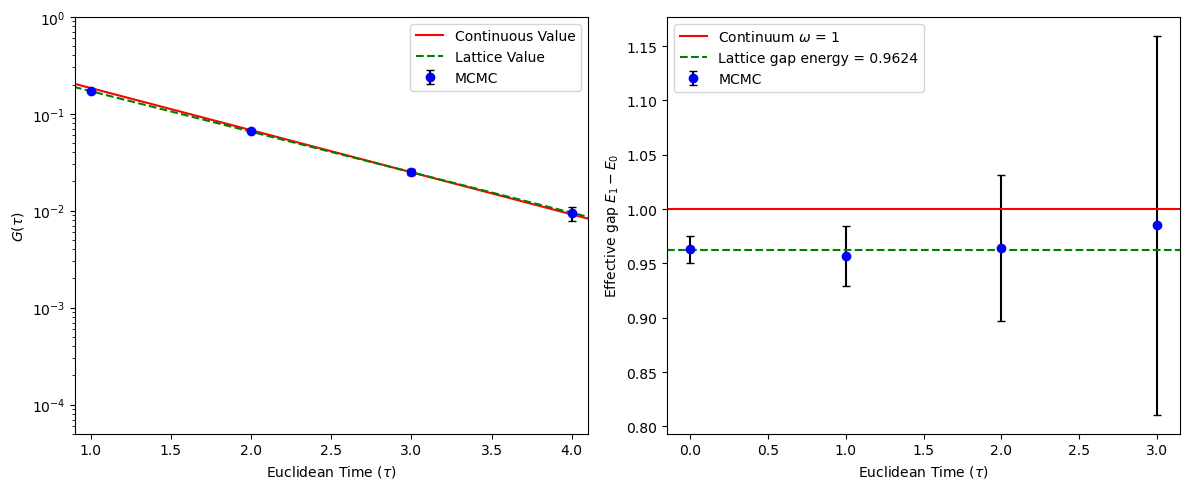

In [7]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))
ax[0].plot(tau, C_cont, '-', c='red', label="Continuous Value")
ax[0].plot(tau, C_analytical, '--', c='green', label="Lattice Value")
ax[0].errorbar(tau, x_corr, yerr=x_corr_err, fmt='o', c='blue', ecolor='black', capsize=3, label="MCMC")
ax[0].set_yscale("log")
ax[0].set_xlim(0.9, 4.1)
ax[0].set_xlabel(r'Euclidean Time ($\tau$)')
ax[0].set_ylim(0.00005, 1)
ax[0].set_ylabel(r"$G(\tau)$")
#ax[0].set_title("MCMC vs Analytical Correlation")
ax[0].legend()

ax[1].errorbar(np.arange(len(gap)) * delta_tau, gap, yerr=gap_err, fmt='o', c='blue', ecolor='black', capsize=3, label="MCMC")
ax[1].axhline(omega, c='red', label=rf"Continuum $\omega$ = {omega}")
ax[1].axhline(gap_analytical, c='green', ls='--', label=fr'Lattice gap energy = {np.round(gap_analytical, 4)}')
ax[1].set_xlim()
ax[1].set_xlabel(r"Euclidean Time ($\tau$)")
ax[1].set_ylabel(r"Effective gap $E_1-E_0$")
#ax[1].set_title("Effective energy gap")
ax[1].legend()

plt.tight_layout()
plt.show()